# NASA POWER case study: Yogyakarta and Jakarta

This notebook retrieves **real NASA POWER monthly T2M data**, independently calculates day-weighted complete-year means and classical OLS trends with SciPy, and checks the results against Terra-Lens JavaScript using the same responses. The examples are model-grid point estimates, not measurements of whole cities. NASA may revise the data, so reruns can differ from the saved output.

Run from a clone of this repository with Python 3, Node 20+, and `pip install -r notebooks/requirements.txt`. Internet access to NASA POWER is required.

In [1]:
from pathlib import Path
import sys, json, math, subprocess, tempfile
from urllib.parse import urlencode
from datetime import datetime, timezone
import matplotlib.pyplot as plt
from scipy.stats import linregress, t

root = Path.cwd()
if not (root / 'scripts' / 'verify-scipy.py').exists():
    root = root.parent
assert (root / 'scripts' / 'verify-scipy.py').exists(), 'Run from the repo or notebooks directory'
sys.path.insert(0, str(root / 'scripts'))
from importlib import import_module
verify = import_module('verify-scipy')
print('Source: NASA POWER monthly point API; retrieved', datetime.now(timezone.utc).isoformat())

Matplotlib is building the font cache; this may take a moment.


Source: NASA POWER monthly point API; retrieved 2026-11-14T08:27:08.017723+00:00


## Retrieve and compare independent implementations

Each request is stored only for the duration of the check. Both implementations receive the same NASA response. Years missing any valid month are excluded; remaining months are weighted by calendar days.

In [2]:
cases = {'Yogyakarta': (-7.7956, 110.3695), 'Jakarta': (-6.2088, 106.8456)}
colors = {'Yogyakarta': '#62d6e4', 'Jakarta': '#f6b975'}
results = {}
for name, (lat, lon) in cases.items():
    url = verify.BASE + '?' + urlencode({'parameters':'T2M','community':'AG','longitude':lon,
                                         'latitude':lat,'start':2001,'end':2024,'format':'JSON'})
    payload = verify.download(url)
    months, rows = verify.annual_series(payload)
    if len(rows) < 10: raise ValueError(f'{name}: fewer than 10 complete years')
    years, values = zip(*rows)
    fit = linregress(years, values)
    margin = t.ppf(.975, len(rows)-2) * fit.stderr
    python = {'n':len(rows), 'slope':fit.slope*10, 'lower':(fit.slope-margin)*10,
              'upper':(fit.slope+margin)*10, 'p':fit.pvalue}
    with tempfile.NamedTemporaryFile(mode='w', suffix='.json') as f:
        json.dump(payload, f); f.flush()
        js = json.loads(subprocess.run(['node','--input-type=module','-e',verify.JS,f.name],
                            cwd=root,check=True,capture_output=True,text=True).stdout)
    for metric in python:
        assert math.isclose(python[metric], js[metric], rel_tol=1e-8, abs_tol=1e-9), (name,metric,python[metric],js[metric])
    results[name] = {'years':years,'values':values,'fit':fit,'stats':python,'url':url}
    print(f"{name}: {months} months, {len(rows)} complete years; {python['slope']:+.4f} °C/decade; "
          f"95% CI [{python['lower']:+.4f}, {python['upper']:+.4f}]; p={python['p']:.5g}. SciPy = JavaScript: pass")
    print(url)

Yogyakarta: 288 months, 24 complete years; +0.1791 °C/decade; 95% CI [+0.0348, +0.3235]; p=0.017319. SciPy = JavaScript: pass
https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M&community=AG&longitude=110.3695&latitude=-7.7956&start=2001&end=2024&format=JSON


Jakarta: 288 months, 24 complete years; +0.2238 °C/decade; 95% CI [+0.0962, +0.3515]; p=0.0014545. SciPy = JavaScript: pass
https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=T2M&community=AG&longitude=106.8456&latitude=-6.2088&start=2001&end=2024&format=JSON


## Annual temperature and fitted trends

Solid lines are calendar-day-weighted annual means; dashed lines are the full-period OLS fits. Both locations use the same vertical scale.

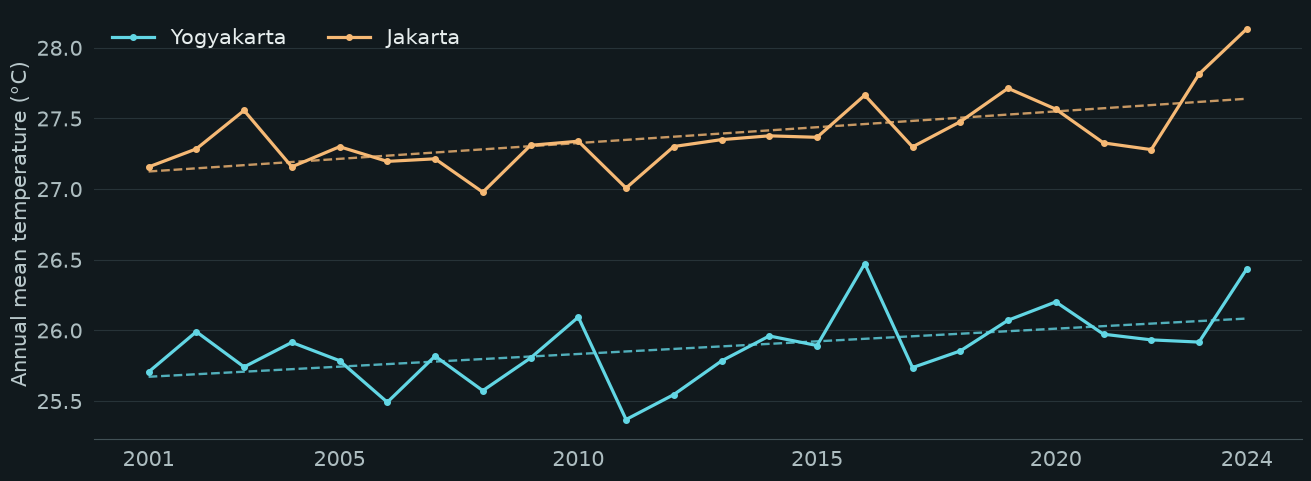

In [3]:
plt.rcParams.update({'font.family':'sans-serif','font.size':15,'text.color':'#e7eeee',
                     'axes.labelcolor':'#b8c7ca','xtick.color':'#adbdc0','ytick.color':'#adbdc0',
                     'axes.edgecolor':'#425156','figure.facecolor':'#11191d','axes.facecolor':'#11191d',
                     'savefig.facecolor':'#11191d'})
fig, ax = plt.subplots(figsize=(13,4.7), layout='constrained')
for name, r in results.items():
    x, y, fit = r['years'], r['values'], r['fit']
    ax.plot(x,y,color=colors[name],lw=2.3,marker='o',markersize=4,label=name)
    ax.plot(x,[fit.intercept + fit.slope * year for year in x],color=colors[name],lw=1.7,ls='--',alpha=.8)
ax.set_ylabel('Annual mean temperature (°C)')
ax.set_xticks([2001,2005,2010,2015,2020,2024]); ax.grid(axis='y',color='#344247',alpha=.65)
ax.spines[['top','right','left']].set_visible(False); ax.tick_params(length=0,pad=8)
ax.legend(loc='upper left',ncol=2,frameon=False,labelcolor='#e7eeee')
fig.savefig(root/'demo'/'annual-temperature.png',dpi=160); plt.show()

## Classical slope intervals

These intervals are conditional on the classical OLS assumptions. The separate estimates do not establish a significant difference between the two slopes. Autocorrelation, model uncertainty and repeated searches can make inference optimistic.

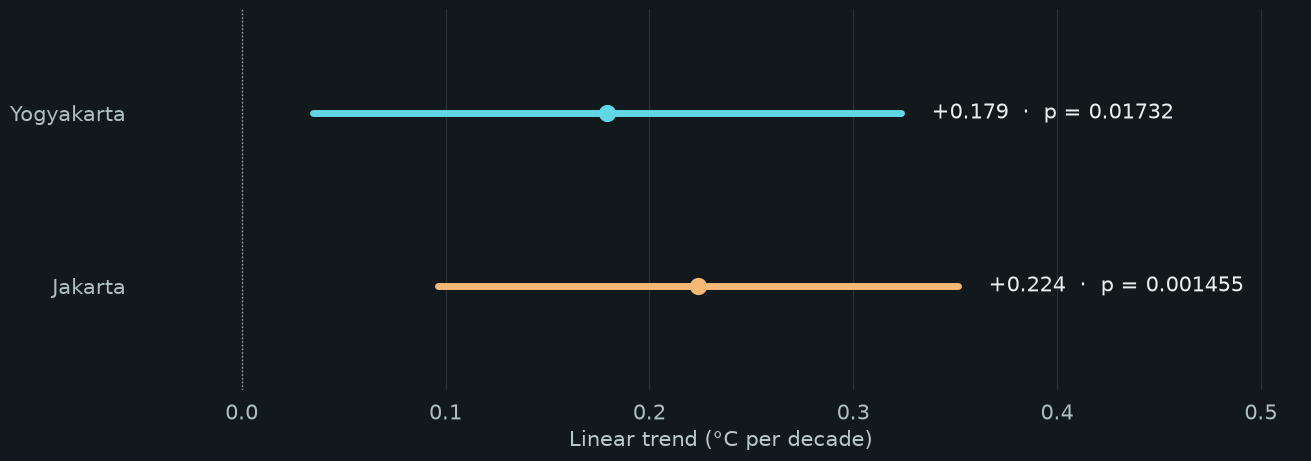

In [4]:
fig, ax = plt.subplots(figsize=(13,4.5), layout='constrained')
for i, (name,r) in enumerate(results.items()):
    s = r['stats']; y = 1-i
    ax.plot([s['lower'],s['upper']],[y,y],color=colors[name],lw=5,solid_capstyle='round')
    ax.scatter([s['slope']],[y],s=130,color=colors[name],zorder=3)
    ax.text(s['upper']+.015,y,f"{s['slope']:+.3f}  ·  p = {s['p']:.4g}",va='center',color='#e7eeee',fontsize=15)
ax.axvline(0,color='#9ba9ab',lw=1,ls=':'); ax.set_yticks([1,0],list(results))
ax.set_xlabel('Linear trend (°C per decade)'); ax.set_xlim(-.05,.52); ax.set_ylim(-.6,1.6)
ax.grid(axis='x',color='#344247',alpha=.65); ax.spines[['top','right','left','bottom']].set_visible(False)
ax.tick_params(length=0,pad=10)
fig.savefig(root/'demo'/'slope-intervals.png',dpi=160); plt.show()

## Interpretation and limitations

NASA POWER provides model-derived point estimates. These results do not identify a cause or predict future conditions. An OLS p-value and interval depend on assumptions that this notebook does not establish, especially independent residuals. The point estimates do not represent city-wide averages. The challenge Resources-tab eligibility of NASA POWER is a separate unresolved question; this notebook does not claim to resolve it.

Sources: [NASA POWER monthly API](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/) · [Methods](../docs/METHODOLOGY.md) · [Case study](../docs/CASE_STUDY.md).